# Report tables and figures

Reads what `01_pipeline.ipynb` wrote, without re-running anything, and builds the tables and numbers for each section of the report. Every table is also saved as a CSV in `reports/tables/`.

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

SMOKE_TEST = False   # must match the setting used in 01_pipeline.ipynb

ROOT = Path.cwd()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT_ROOT = ROOT / "smoke" if SMOKE_TEST else ROOT
INTERIM, PROCESSED = OUT_ROOT / "data" / "interim", OUT_ROOT / "data" / "processed"
RES, FIG = OUT_ROOT / "results", OUT_ROOT / "reports" / "figures"
TABLES = OUT_ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)


def load_table(path):
    """Template / message tables store token and lemma lists as JSON strings."""
    df = pd.read_csv(path, keep_default_na=False)
    for col in ("tokens", "lemmas"):
        if col in df:
            df[col] = df[col].map(json.loads)
    return df


templates = load_table(INTERIM / "templates_nlp.csv")
messages = load_table(INTERIM / "messages_nlp.csv")
meta = pd.read_parquet(PROCESSED / "windows.parquet")
res = pd.read_csv(RES / "metrics.csv")
print(f"{len(templates)} templates, {len(messages):,} masked messages, {len(meta):,} windows")

392 templates, 16,107 masked messages, 14,501 windows


## Data section
### Dataset statistics (Table: dataset summary)

In [3]:
eda = json.loads((RES / "eda_summary.json").read_text())
keys = ["lines", "anomalous_lines", "line_anomaly_rate", "days_spanned", "nodes", "templates", "masked_messages",
        "masked_messages_per_template_median", "windows", "window_anomaly_rate", "median_lines_per_window",
        "vocab_raw_tokens", "vocab_lemmas", "templates_with_any_alert_line", "alert_templates_always_alert"]
data_table = pd.Series({k: eda.get(k) for k in keys}, name="value").to_frame()
data_table.to_csv(TABLES / "table_data_summary.csv")
data_table

,value
lines,4.747963e+06
anomalous_lines,3.484600e+05
line_anomaly_rate,7.339147e-02
days_spanned,2.147000e+02
nodes,6.925200e+04
templates,3.920000e+02
masked_messages,1.610700e+04
masked_messages_per_template_median,1.000000e+00
windows,1.450100e+04
window_anomaly_rate,7.254672e-02


### Severity level vs label (the leakage argument)
The Level field almost decides the label, which is why it is excluded from model inputs.

In [4]:
pd.DataFrame(eda["level_by_label"]).fillna(0).astype(int)

,false,true
"0x00544eb8,",2,0
ERROR,112355,0
FAILURE,1652,62
FATAL,506797,348398
INFO,3735813,0
Kill,306,0
SEVERE,19213,0
WARNING,23357,0
microseconds,4,0
single,4,0


### Largest templates and what lemmatisation did to them

In [5]:
templates.sort_values("size", ascending=False)[["template", "lemmas", "size"]].head(15)

,template,lemmas,size
2,generating core.<NUM>,"[generate, core]",1706751
264,iar <HEX> dear <HEX>,"[iar, dear]",442966
154,<NUM> floating point alignment exceptions,"[float, point, alignment, exception]",257317
5,"CE sym <NUM>, at <HEX>, mask <HEX>","[ce, sym, mask]",201206
11,<NUM> double-hummer alignment exceptions,"[double, hummer, alignment, exception]",175184
18,data TLB error interrupt,"[data, tlb, error, interrupt]",152734
377,<NUM> microseconds spent in the rbs signal han...,"[microsecond, spend, rbs, signal, handler, cal...",135090
378,<NUM> total interrupts. <NUM> critical input i...,"[total, interrupt, critical, input, interrupt,...",135090
155,<HEX> double-hummer alignment exceptions,"[double, hummer, alignment, exception]",120580
0,instruction cache parity error corrected,"[instruction, cache, parity, error, correct]",105924


### One template, many masked messages
This shows how much variation Drain3 merges into a single template, and what the parser-free view keeps.

In [6]:
ids = pd.read_parquet(INTERIM / "bgl_parsed.parquet", columns=["cluster_id", "msg_id", "is_anomaly"])
per_tpl = ids.groupby("cluster_id")["msg_id"].nunique().sort_values(ascending=False)
per_tpl.head(10).to_frame("masked messages").join(templates.set_index("cluster_id")["template"])

,masked messages,template
cluster_id,,
136,10084,Ido chip status changed: <*> ip=<IP> v=<NUM> t...
193,2601,New ido chip inserted into the database: <*> i...
109,1346,PrepareForService shutting down <*> mCardSernu...
344,583,PrepareForService shutting down <*> card(mLctn...
140,425,While initializing <*> card iDo machine with L...
149,112,PrepareForService is being done on this part (...
226,96,While initializing service card iDo with LP of...
11,38,ciod: Error loading <*> invalid or missing pro...
157,21,Problem communicating with <*> <*> iDo machine...


### Templates that are always alerts (Landauer et al.'s separability point)

In [7]:
share = ids.groupby("cluster_id")["is_anomaly"].agg(alert_share="mean", lines="size")
share = share.join(templates.set_index("cluster_id")["template"])
share[share["alert_share"] > 0].sort_values("lines", ascending=False).head(20).round(3)

,alert_share,lines,template
cluster_id,,,
19,1.000,152734,data TLB error interrupt
122,1.000,63493,data storage interrupt
347,1.000,28802,ciod: Error reading message prefix on CioStrea...
268,1.000,26426,Lustre mount FAILED : <*> : point <PATH>
216,1.000,23219,ciod: Error reading message prefix after <*> o...
258,1.000,18587,rts: kernel terminated for reason <NUM>
21,0.024,6755,machine check <*>
35,0.000,6544,floating point <*> <*>
286,1.000,6145,"Error receiving packet on tree network, <*> <*..."


## Results: RQ1, template-based vs parser-free
Isolation forest and autoencoder results are the mean over several seeds (`n_seeds`), with the standard
deviation in `auc_pr_sd`. PCA and the supervised reference are deterministic (sd 0).

### Main table: best detector and regime per feature set, chosen on validation

In [8]:
grid = res[res["regime"].isin(["unsupervised", "semi_supervised"])]
best = grid.loc[grid.groupby("feature_set")["val_auc_pr"].idxmax()]
rq1 = best[["representation", "feature_set", "model", "regime", "auc_pr", "auc_pr_sd", "auc_pr_novel",
            "precision", "recall", "f1", "n_seeds"]]
rq1 = rq1.sort_values(["representation", "auc_pr"], ascending=[False, False]).round(3)
rq1.to_csv(TABLES / "table_rq1_best_per_feature_set.csv", index=False)
rq1

,representation,feature_set,model,regime,auc_pr,auc_pr_sd,auc_pr_novel,precision,recall,f1,n_seeds
8,template,tfidf,iforest,unsupervised,0.614,0.037,0.689,0.536,0.442,0.480,5
4,template,count,autoencoder,semi_supervised,0.610,0.006,0.691,1.000,0.324,0.490,5
18,template,sbert,autoencoder,semi_supervised,0.388,0.022,0.300,0.452,0.601,0.508,5
22,parser-free,pf_tfidf,iforest,unsupervised,0.610,0.018,0.680,0.492,0.712,0.580,5
32,parser-free,pf_sbert,autoencoder,semi_supervised,0.403,0.042,0.346,0.311,0.696,0.400,5


### Fair pairs: same method, different unit
A positive delta means parser-free did better. `clear_difference` is True when the delta is larger than the
two seed standard deviations combined and at least 0.01 AUC-PR; otherwise the two representations are
effectively tied.

In [9]:
pairs = [("tfidf", "pf_tfidf"), ("sbert", "pf_sbert")]
rows = []
for tpl, pf in pairs:
    for (model, regime), g in grid.groupby(["model", "regime"]):
        a, b = g[g.feature_set == tpl], g[g.feature_set == pf]
        if len(a) and len(b):
            a, b = a.iloc[0], b.iloc[0]
            delta = b.auc_pr - a.auc_pr
            noise = np.hypot(a.auc_pr_sd, b.auc_pr_sd)
            rows.append({"pair": f"{tpl} vs {pf}", "model": model, "regime": regime,
                         "template_auc_pr": a.auc_pr, "template_sd": a.auc_pr_sd,
                         "parser_free_auc_pr": b.auc_pr, "parser_free_sd": b.auc_pr_sd,
                         "delta": delta, "clear_difference": abs(delta) > noise and abs(delta) >= 0.01,
                         "template_novel": a.auc_pr_novel, "parser_free_novel": b.auc_pr_novel})
fair = pd.DataFrame(rows).round(3)
fair.to_csv(TABLES / "table_rq1_fair_pairs.csv", index=False)
print("Parser-free clearly better:", int(((fair.delta > 0) & fair.clear_difference).sum()),
      "| clearly worse:", int(((fair.delta < 0) & fair.clear_difference).sum()),
      "| tied:", int((~fair.clear_difference).sum()), "of", len(fair))
fair

Parser-free clearly better: 4 | clearly worse: 1 | tied: 7 of 12


,pair,model,regime,template_auc_pr,template_sd,parser_free_auc_pr,parser_free_sd,delta,clear_difference,template_novel,parser_free_novel
0,tfidf vs pf_tfidf,autoencoder,semi_supervised,0.489,0.013,0.484,0.007,-0.005,False,0.517,0.513
1,tfidf vs pf_tfidf,autoencoder,unsupervised,0.218,0.002,0.447,0.019,0.229,True,0.228,0.486
2,tfidf vs pf_tfidf,iforest,semi_supervised,0.236,0.018,0.221,0.009,-0.015,False,0.292,0.270
3,tfidf vs pf_tfidf,iforest,unsupervised,0.614,0.037,0.610,0.018,-0.004,False,0.689,0.680
4,tfidf vs pf_tfidf,pca,semi_supervised,0.341,0.000,0.446,0.000,0.105,True,0.357,0.472
5,tfidf vs pf_tfidf,pca,unsupervised,0.179,0.000,0.253,0.000,0.075,True,0.185,0.272
6,sbert vs pf_sbert,autoencoder,semi_supervised,0.388,0.022,0.403,0.042,0.016,False,0.300,0.346
7,sbert vs pf_sbert,autoencoder,unsupervised,0.097,0.005,0.108,0.008,0.011,True,0.098,0.111
8,sbert vs pf_sbert,iforest,semi_supervised,0.460,0.024,0.472,0.081,0.012,False,0.613,0.628
9,sbert vs pf_sbert,iforest,unsupervised,0.446,0.055,0.438,0.043,-0.007,False,0.618,0.607


### Full grid, AUC-PR (appendix table)

In [10]:
full = grid.pivot_table(index="feature_set", columns=["regime", "model"], values="auc_pr").round(3)
full.to_csv(TABLES / "table_rq1_full_grid.csv")
full

regime      semi_supervised                unsupervised               
model           autoencoder iforest    pca  autoencoder iforest    pca
feature_set                                                           
count                 0.610   0.265  0.654        0.594   0.555  0.630
pf_sbert              0.403   0.472  0.426        0.108   0.438  0.134
pf_tfidf              0.484   0.221  0.446        0.447   0.610  0.253
sbert                 0.388   0.460  0.445        0.097   0.446  0.135
tfidf                 0.489   0.236  0.341        0.218   0.614  0.179

### Baselines in context: severity rule, classic event-count baseline, supervised ceiling

In [11]:
base = pd.concat([
    res[res.model == "severity_rule"],
    grid[(grid.feature_set == "count") & grid.model.isin(["pca", "iforest"])],
    res[res.model == "supervised_ref"],
])[["feature_set", "model", "regime", "auc_pr", "f1"]].round(3)
base.to_csv(TABLES / "table_baselines.csv", index=False)
base

,feature_set,model,regime,auc_pr,f1
0,level_field,severity_rule,rule,0.665,0.686
1,count,iforest,unsupervised,0.555,0.500
2,count,iforest,semi_supervised,0.265,0.028
5,count,pca,unsupervised,0.630,0.254
6,count,pca,semi_supervised,0.654,0.500
7,count,supervised_ref,supervised,0.695,0.713
14,tfidf,supervised_ref,supervised,0.980,0.944
21,sbert,supervised_ref,supervised,0.985,0.933
28,pf_tfidf,supervised_ref,supervised,0.994,0.950
35,pf_sbert,supervised_ref,supervised,0.992,0.957


## Results: RQ2, training regime × chronological vs random
Both splits are run over several seeds. `gap_exceeds_sd` is True when the gap is larger than the chronological
and random standard deviations combined and at least 0.01 AUC-PR. The `supervised_ref` rows are the control: compare the direction
of their gap with the isolation forest rows.

In [12]:
splits = pd.read_csv(RES / "splits_summary.csv").round(3)
splits.to_csv(TABLES / "table_rq2_splits.csv", index=False)
display(splits)
display(pd.read_csv(RES / "splits_profile.csv").round(3))

,feature_set,representation,model,regime,chrono_auc_pr,chrono_auc_pr_sd,random_auc_pr_mean,random_auc_pr_sd,chrono_f1,random_f1_mean,gap_auc_pr,gap_exceeds_sd
0,count,template,iforest,semi_supervised,0.265,0.004,0.124,0.004,0.018,0.187,-0.141,True
1,count,template,iforest,unsupervised,0.550,0.020,0.459,0.017,0.500,0.473,-0.091,True
2,count,template,supervised_ref,supervised,0.695,0.000,0.966,0.004,0.713,0.971,0.271,True
3,pf_sbert,parser-free,iforest,semi_supervised,0.486,0.051,0.280,0.047,0.296,0.379,-0.206,True
4,pf_sbert,parser-free,iforest,unsupervised,0.467,0.024,0.303,0.048,0.232,0.358,-0.165,True
5,pf_sbert,parser-free,supervised_ref,supervised,0.992,0.000,0.997,0.002,0.957,0.970,0.004,False
6,pf_tfidf,parser-free,iforest,semi_supervised,0.217,0.009,0.137,0.017,0.391,0.298,-0.080,True
7,pf_tfidf,parser-free,iforest,unsupervised,0.622,0.008,0.398,0.059,0.618,0.450,-0.224,True
8,pf_tfidf,parser-free,supervised_ref,supervised,0.994,0.000,0.992,0.006,0.950,0.984,-0.003,False
9,sbert,template,iforest,semi_supervised,0.462,0.026,0.329,0.053,0.322,0.385,-0.133,True


,split_mode,seed,train_anomaly_rate,test_anomaly_rate,test_windows_with_unseen_templates,templates_unseen_in_train
0,chronological,42,0.079,0.072,0.748,105
1,random,42,0.074,0.066,0.003,17
2,random,43,0.073,0.072,0.002,24
3,random,44,0.072,0.070,0.005,32


### Regime comparison under the chronological split only

In [13]:
reg = grid.pivot_table(index=["feature_set", "model"], columns="regime", values="auc_pr").round(3)
reg["semi_minus_unsup"] = (reg.get("semi_supervised") - reg.get("unsupervised")).round(3)
reg

regime                   semi_supervised  unsupervised  semi_minus_unsup
feature_set model                                                       
count       autoencoder            0.610         0.594             0.016
            iforest                0.265         0.555            -0.290
            pca                    0.654         0.630             0.024
pf_sbert    autoencoder            0.403         0.108             0.295
            iforest                0.472         0.438             0.034
            pca                    0.426         0.134             0.292
pf_tfidf    autoencoder            0.484         0.447             0.037
            iforest                0.221         0.610            -0.389
            pca                    0.446         0.253             0.193
sbert       autoencoder            0.388         0.097             0.291
            iforest                0.460         0.446             0.014
            pca                    0.445         0.135             0.310
tfidf       autoencoder            0.489         0.218             0.271
            iforest                0.236         0.614            -0.378
            pca                    0.341         0.179             0.162

### Why the regime effect differs: features constant in training
Compare `anomalous_test_windows_using_them` between regimes with the isolation forest AUC-PR.

In [14]:
cf = pd.read_csv(RES / "regime_constant_features.csv").round(3)
cf.to_csv(TABLES / "table_rq2_constant_features.csv", index=False)
cf

,feature_set,regime,content_features,constant_in_training,anomalous_test_windows_using_them,normal_test_windows_using_them,anomalous_with_novelty_signal,normal_with_novelty_signal,iforest_auc_pr
0,count,unsupervised,392,105,0.917,0.735,0.917,0.735,0.555
1,count,semi_supervised,392,221,1.000,0.735,1.000,0.735,0.265
2,tfidf,unsupervised,433,0,0.000,0.000,0.917,0.735,0.614
3,tfidf,semi_supervised,328,0,0.000,0.000,1.000,0.735,0.236
4,sbert,unsupervised,768,4,0.000,0.000,0.917,0.735,0.446
5,sbert,semi_supervised,768,4,0.000,0.000,1.000,0.735,0.460
6,pf_tfidf,unsupervised,575,0,0.000,0.000,0.923,0.747,0.610
7,pf_tfidf,semi_supervised,454,0,0.000,0.000,1.000,0.747,0.221
8,pf_sbert,unsupervised,768,4,0.000,0.000,0.923,0.747,0.438
9,pf_sbert,semi_supervised,768,4,0.000,0.000,1.000,0.747,0.472


## Results: RQ3, natural-language alerts

In [15]:
alerts = pd.DataFrame(json.loads((RES / "alerts_summary.json").read_text())).T
alerts.to_csv(TABLES / "table_rq3_alerts.csv")
alerts

,detector,representation,n_alerts,alert_precision,attribution_hit_rate,top_unit_unseen_rate,midplane_match_rate,lines_per_alert,compression_ratio
best,pf_tfidf|iforest|unsupervised,parser-free,232,0.560345,0.523077,0.646552,0.746154,268.538793,2072.056034
template,count|autoencoder|semi_supervised,template,51,1.0,0.098039,0.039216,0.843137,436.784314,9425.823529
parser_free,pf_tfidf|iforest|unsupervised,parser-free,232,0.560345,0.523077,0.646552,0.746154,268.538793,2072.056034


### Pick worked examples: 3 true alerts and 1 false positive
Use these in the report and on a presentation slide.

In [16]:
a = pd.read_csv(RES / "alerts_best.csv")
for _, r in a[a.true_anomaly == 1].head(3).iterrows():
    print(r["text"], "\n")
fp = a[a.true_anomaly == 0]
print("--- FALSE POSITIVE ---")
print(fp.iloc[0]["text"] if len(fp) else "No false positives among flagged test windows.")

[ALERT 1] 2005-12-04 18:32-18:37 UTC | score higher than 100.0% of validation windows
  Where: 1 node(s), 100% on midplane R71-M0 | component KERNEL
  What (largest contribution first):
  - 2x "lr cr xer ctr" [FATAL] - never seen during training
  - 2x "Special Purpose Registers" [FATAL] - never seen during training
  - 2x "qw trapped" [FATAL] - seen 18x during training
  Volume: 390 lines in window 

[ALERT 2] 2005-12-04 19:07-19:12 UTC | score higher than 100.0% of validation windows
  Where: 1 node(s), 100% on midplane R71-M0 | component KERNEL
  What (largest contribution first):
  - 2x "lr cr xer ctr" [FATAL] - never seen during training
  - 2x "Special Purpose Registers" [FATAL] - never seen during training
  - 2x "qw trapped" [FATAL] - seen 18x during training
  Volume: 390 lines in window 

[ALERT 3] 2005-12-09 17:47-17:52 UTC | score higher than 100.0% of validation windows
  Where: 240 node(s), 62% on midplane R55-M1 | component KERNEL
  What (largest contribution first):
  -

## Figures for the report
All figures are in `reports/figures/`, which is committed with the repo.

**auc_pr_grid.png**

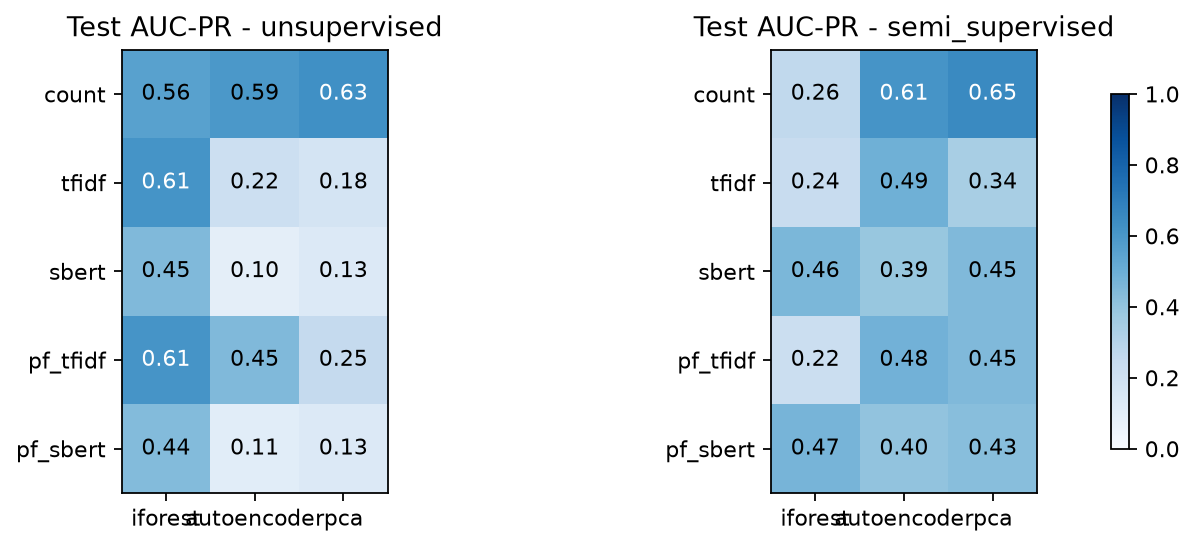

**eda_alert_categories_top20.png**

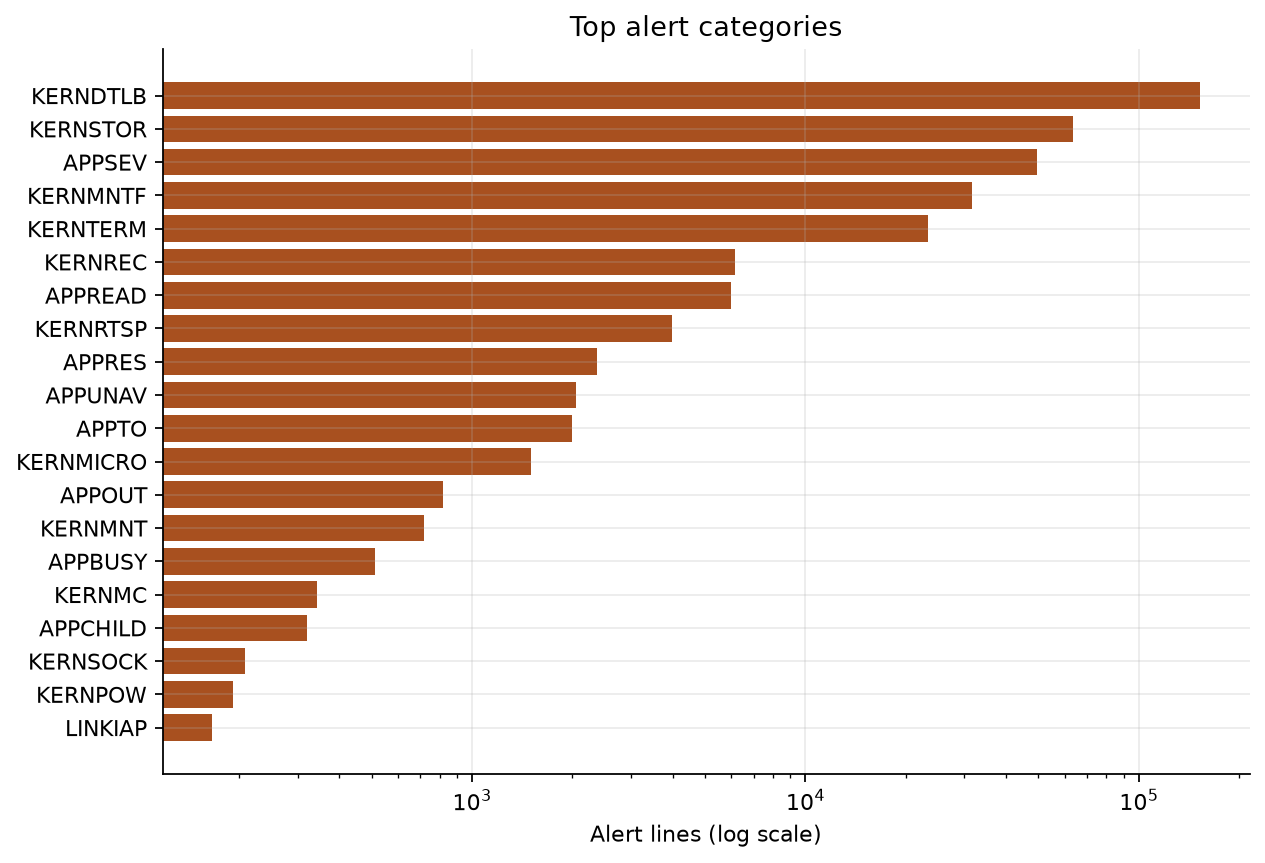

**eda_burstiness.png**

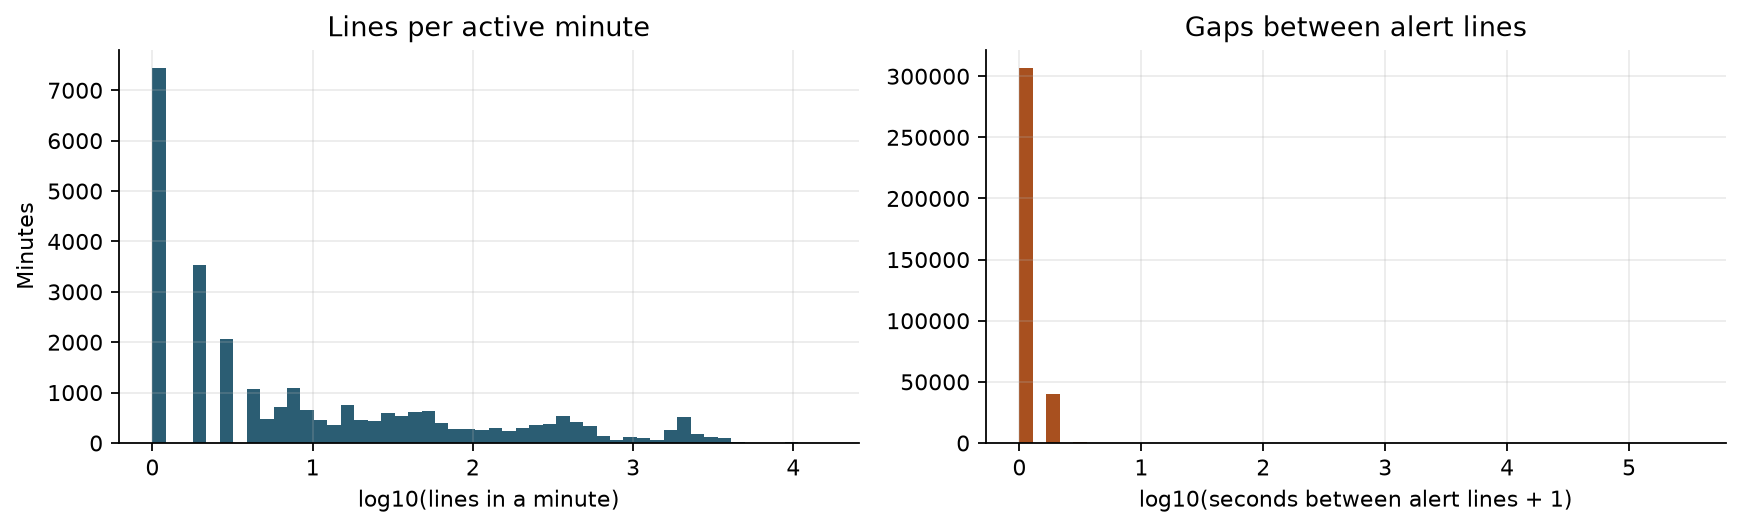

**eda_cumulative_templates.png**

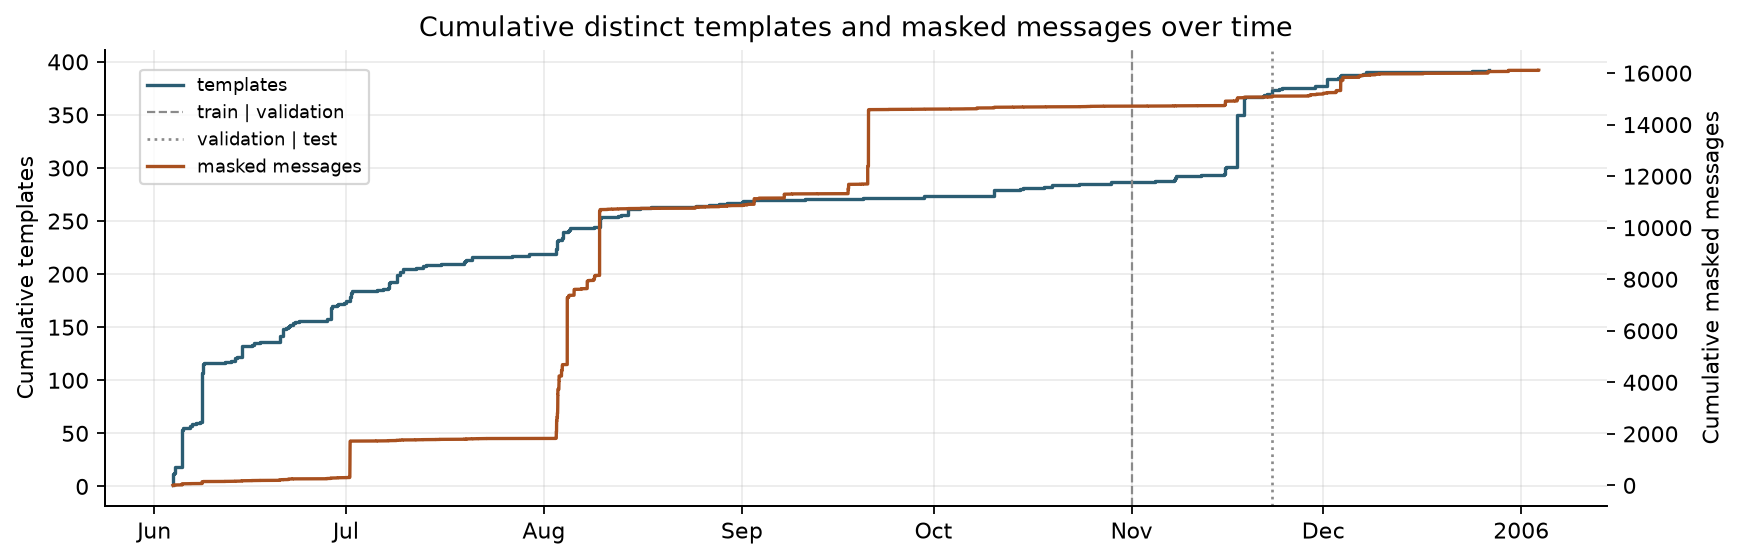

**eda_daily_volume_with_cut.png**

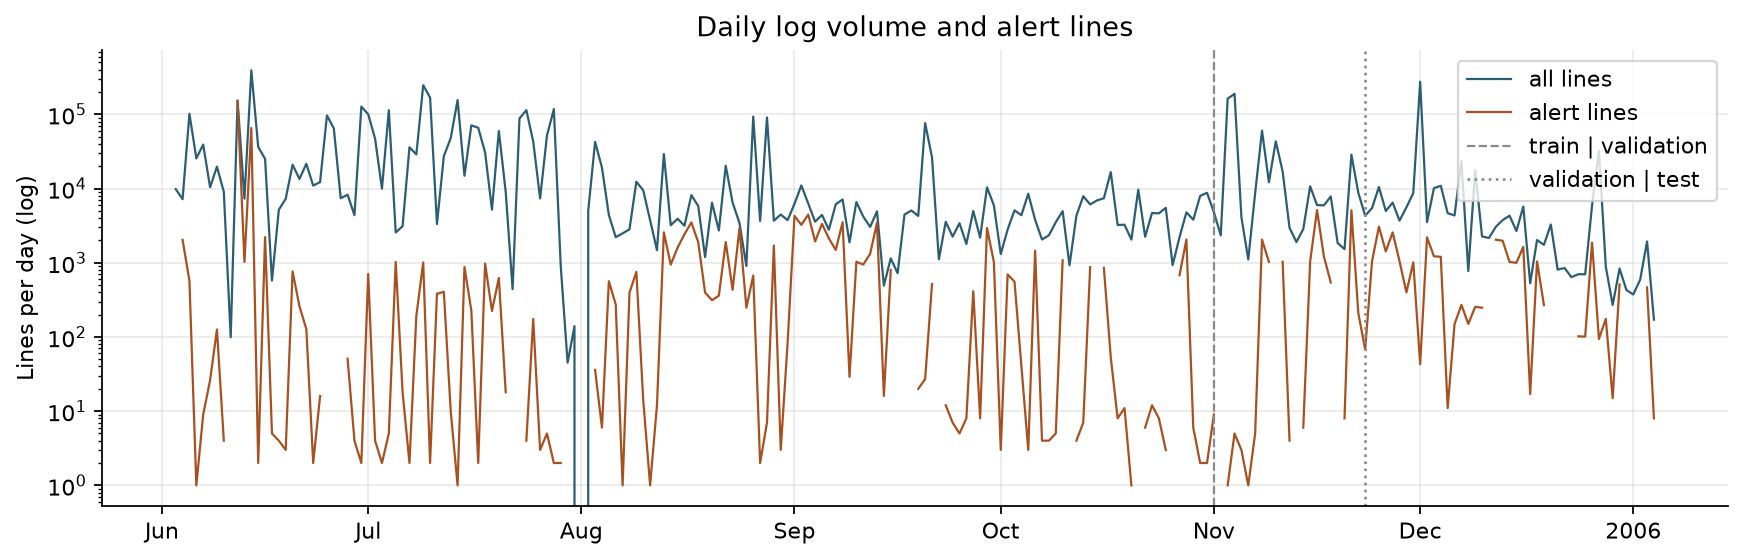

**eda_distinctive_words.png**

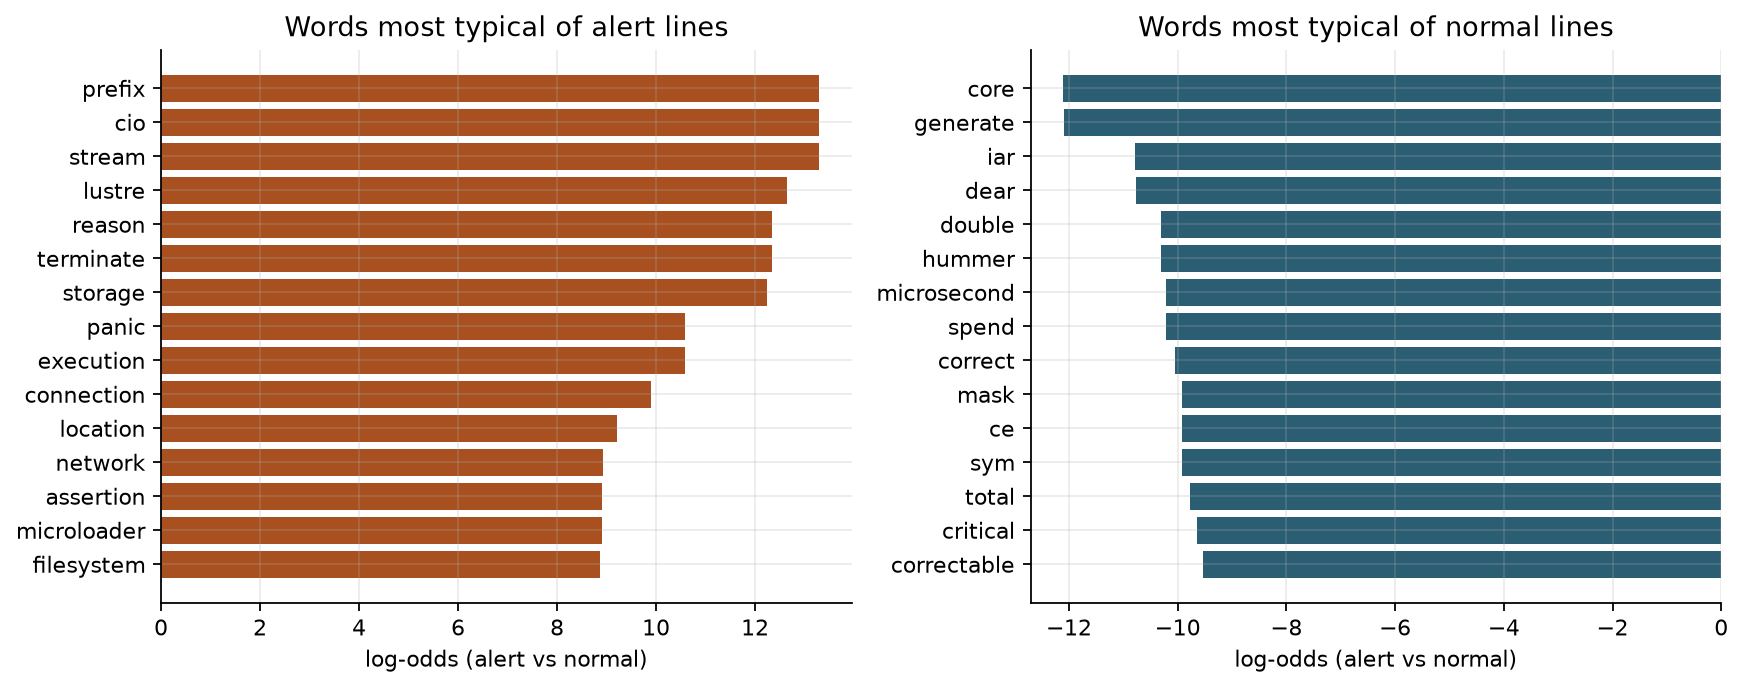

**eda_hour_weekday.png**

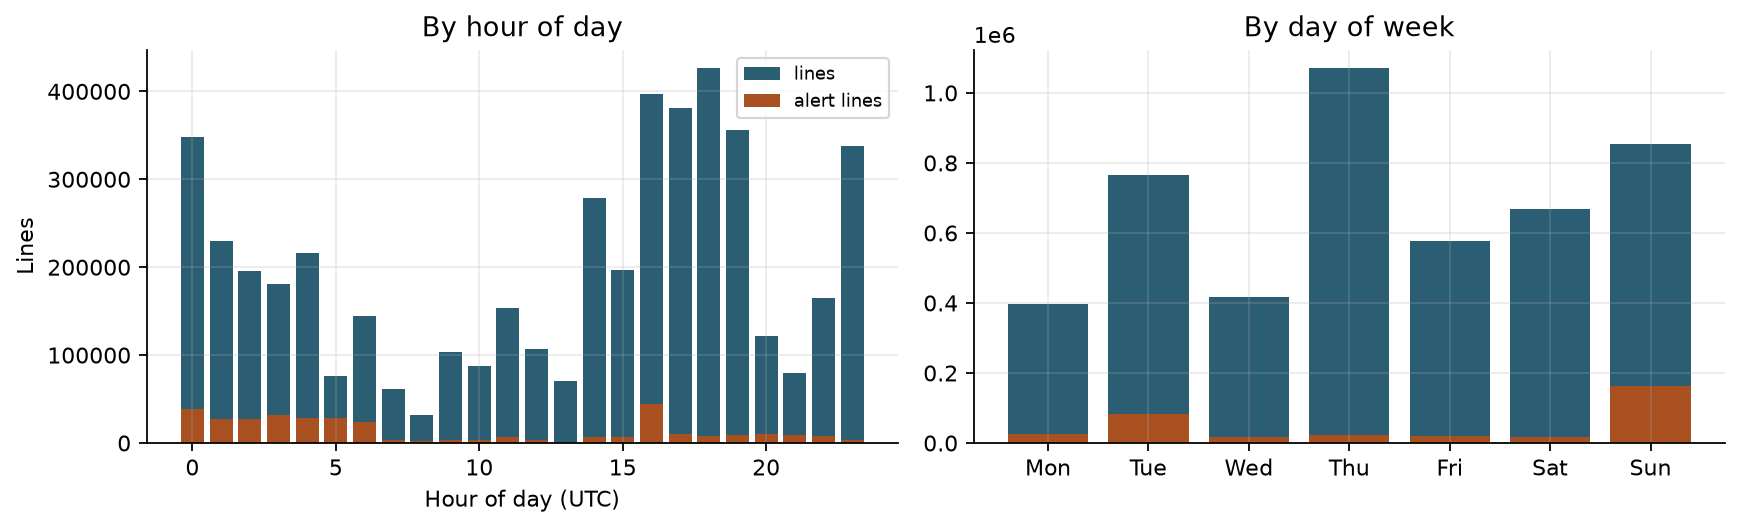

**eda_level_vs_label.png**

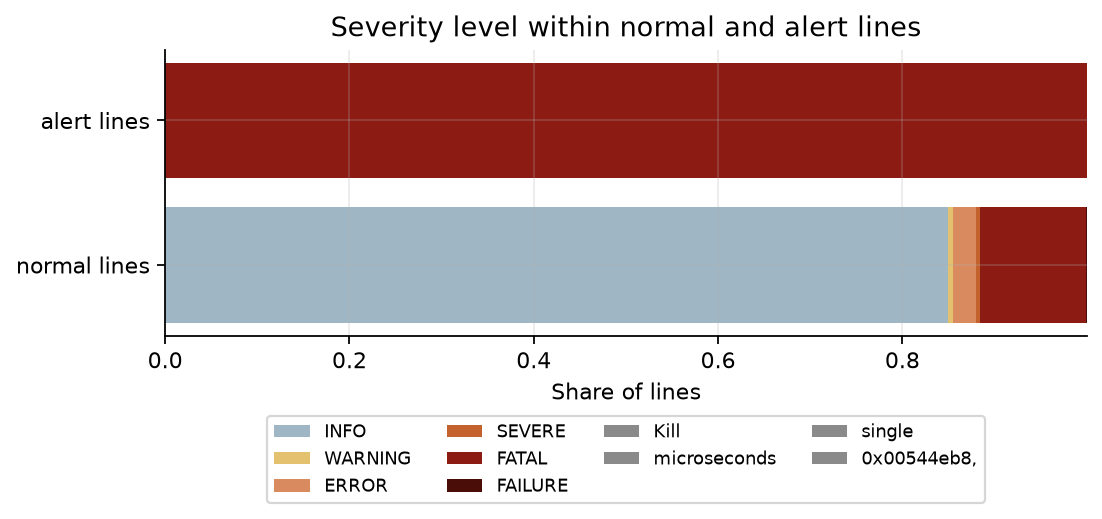

**eda_message_length.png**

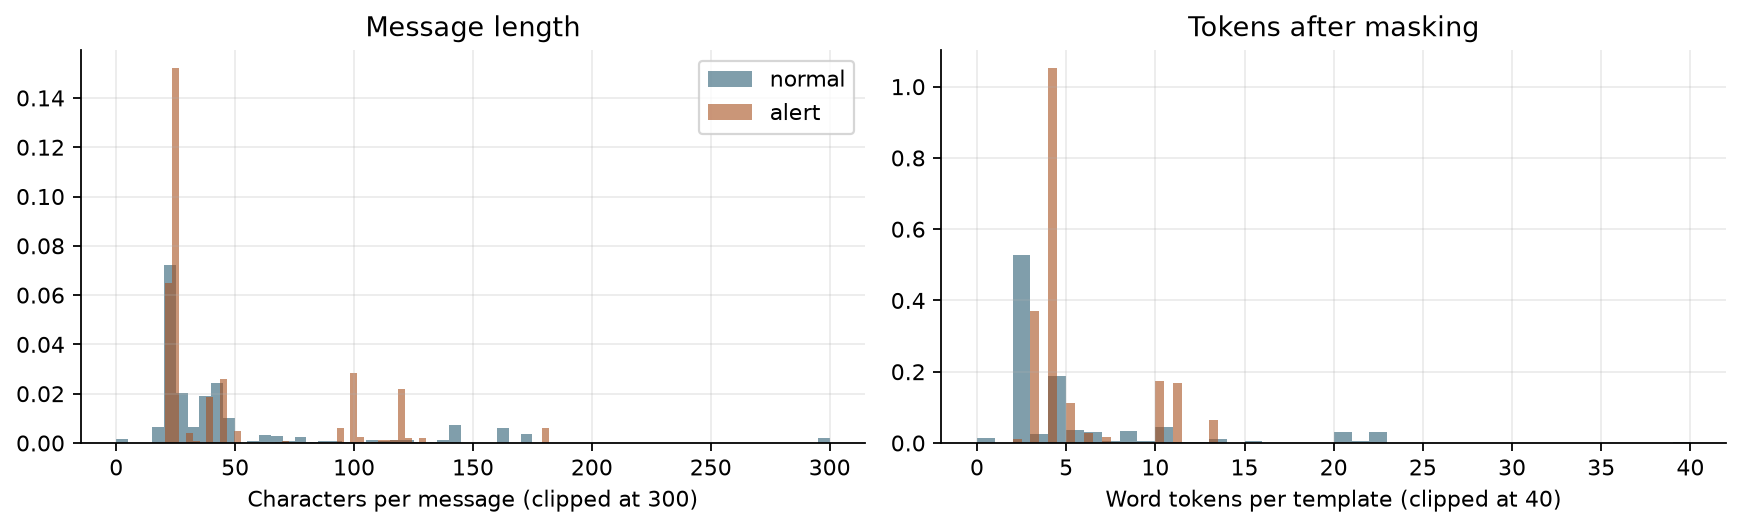

**eda_messages_per_template.png**

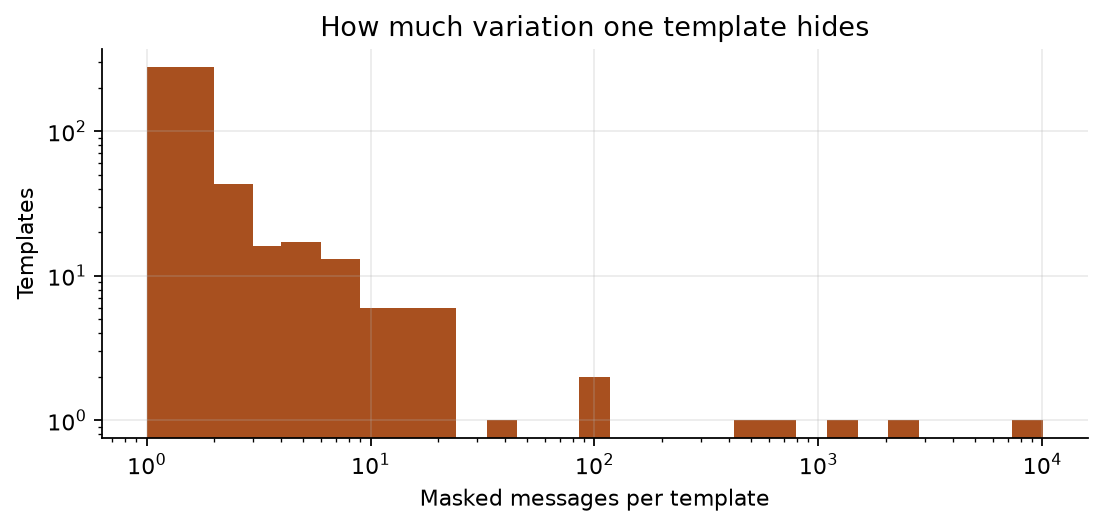

**eda_nodes.png**

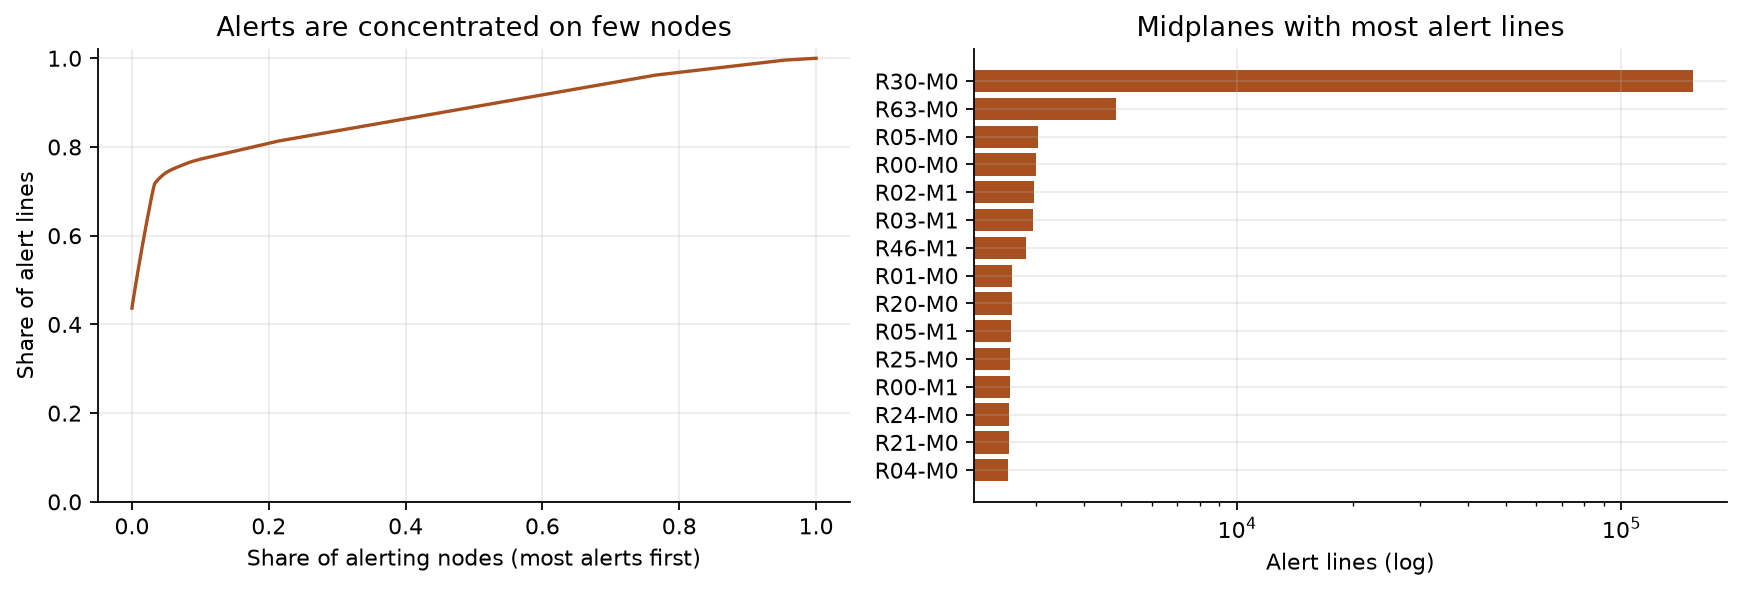

**eda_template_rank_frequency.png**

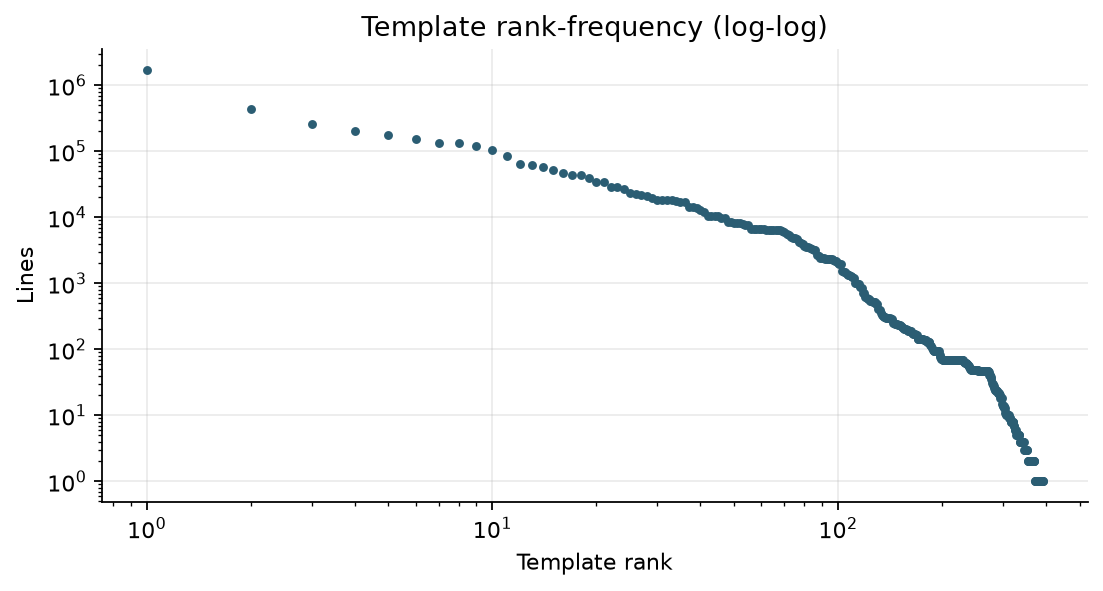

**eda_window_length.png**

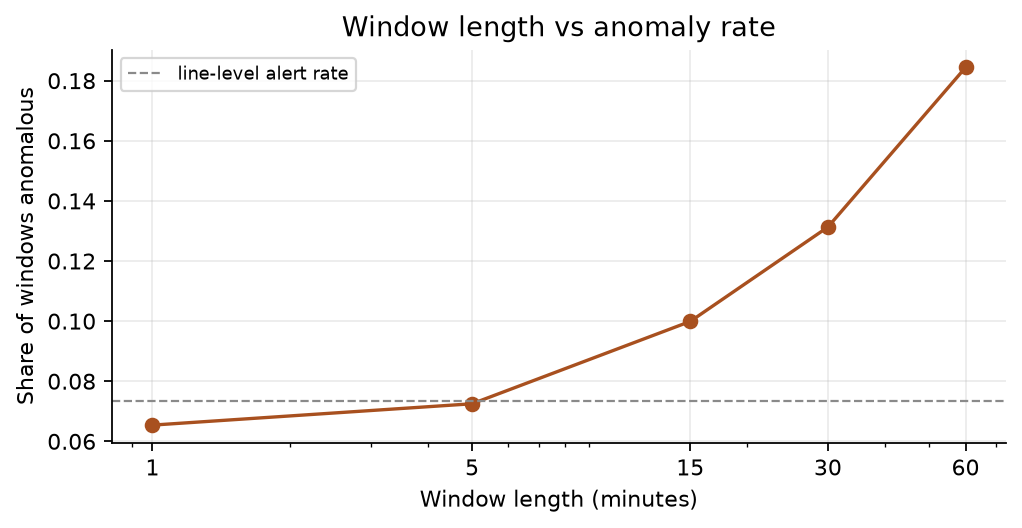

**eda_windows.png**

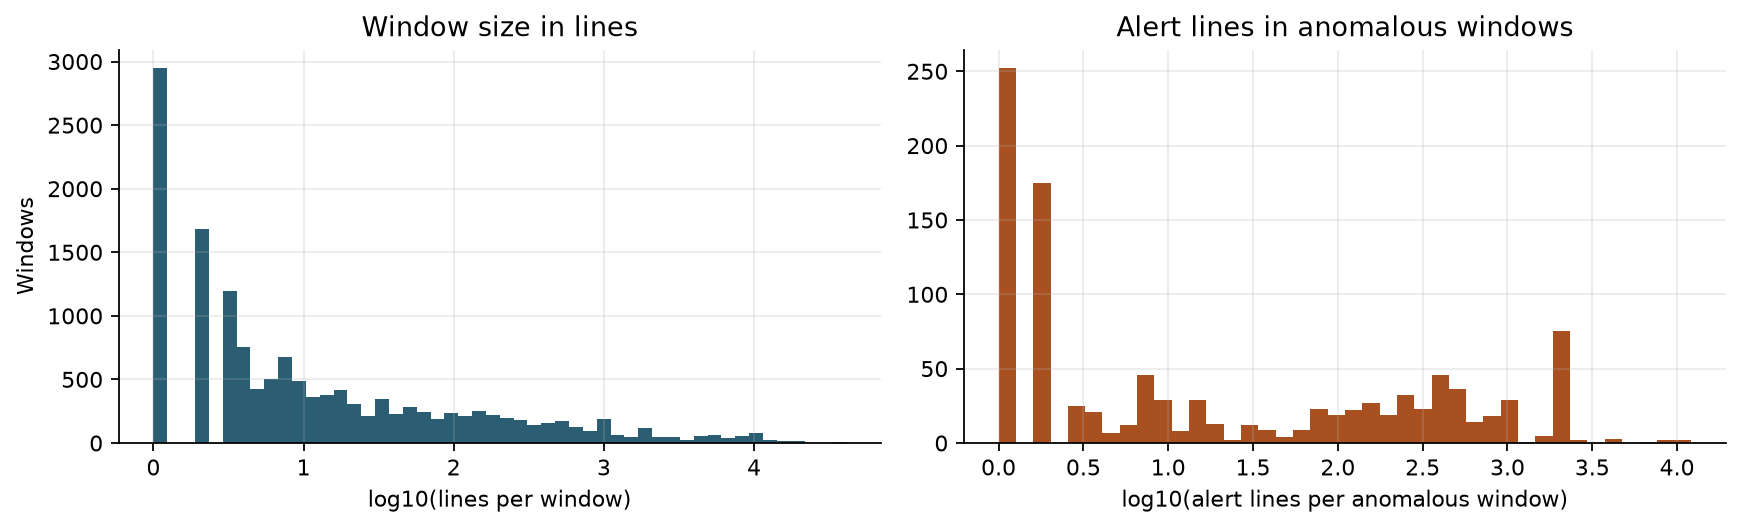

**novelty_weekly.png**

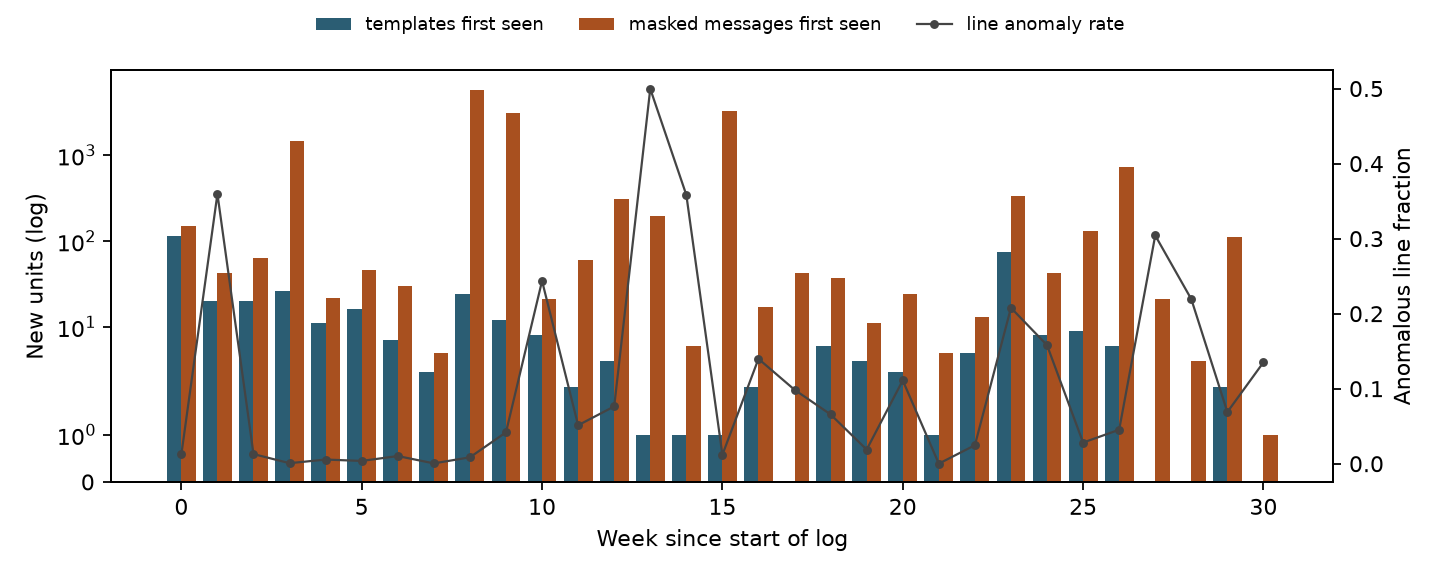

**pr_curves_test.png**

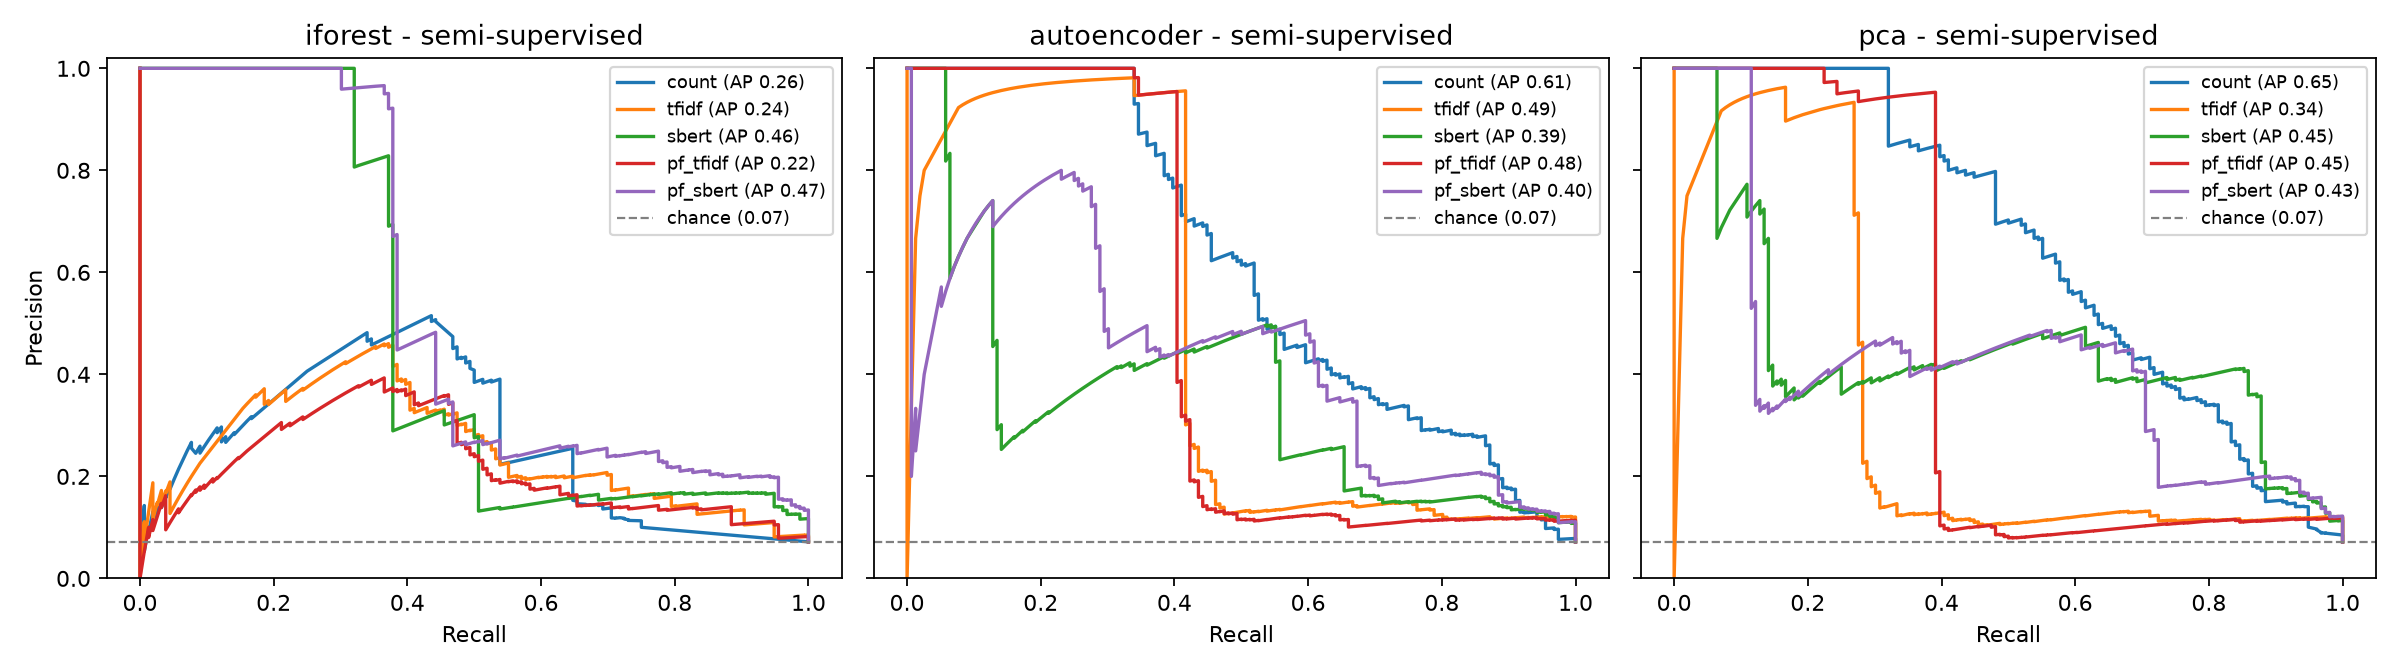

**rq1_template_vs_parser_free.png**

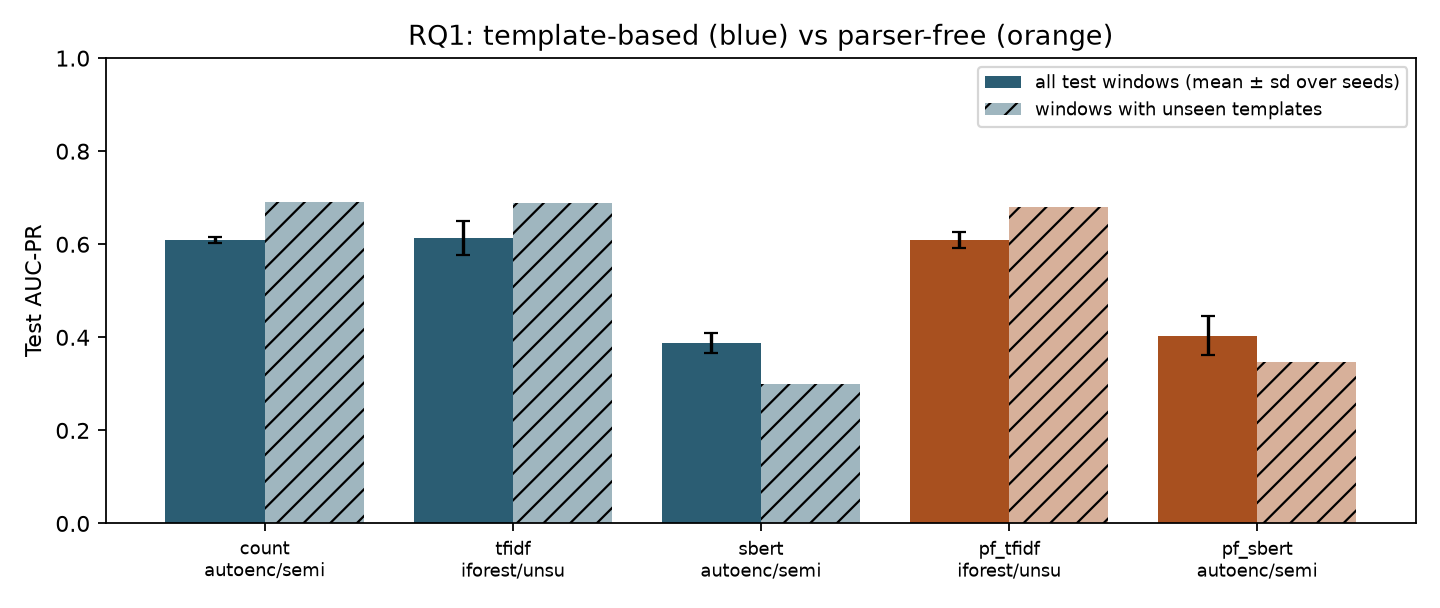

**rq2_chrono_vs_random.png**

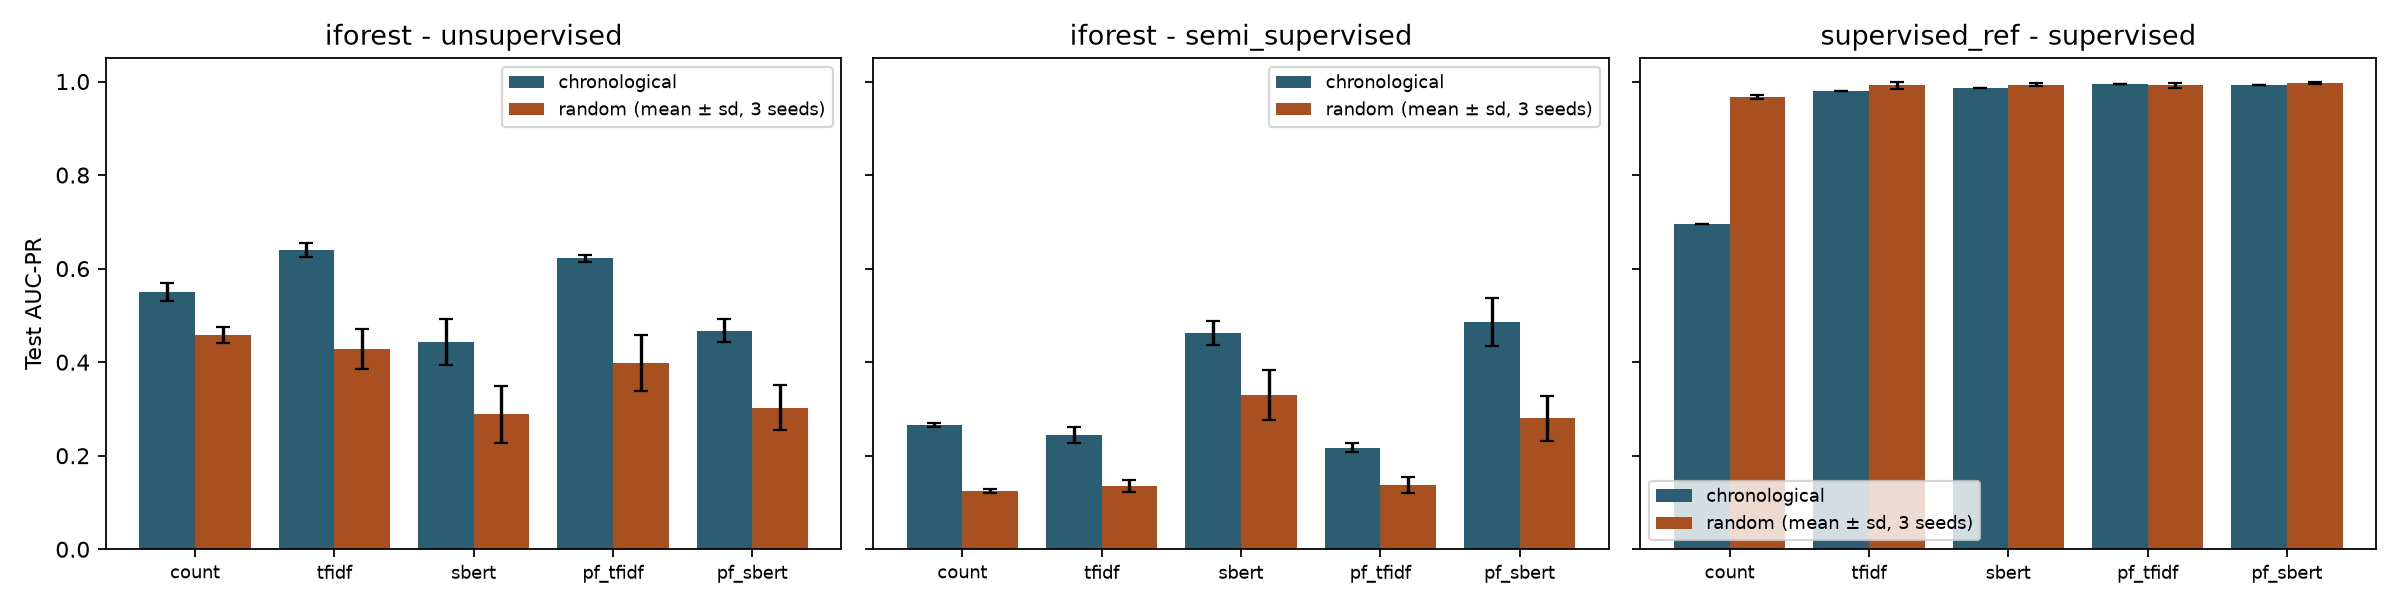

In [17]:
for f in sorted(FIG.glob("*.png")):
    display(Markdown(f"**{f.name}**"))
    display(Image(f, width=700))

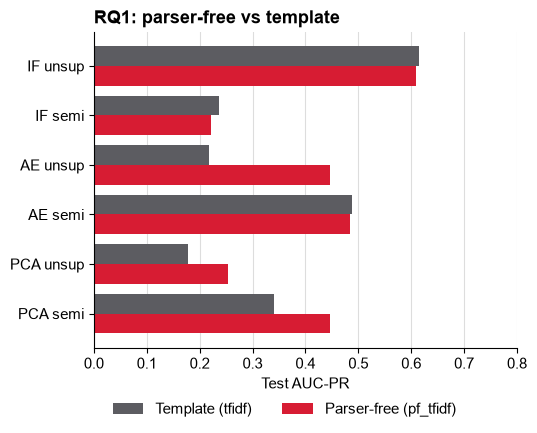

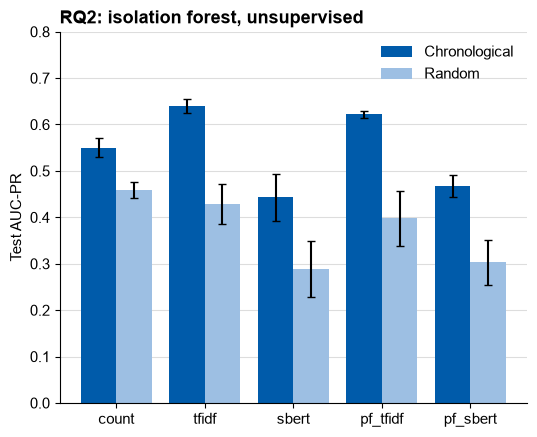

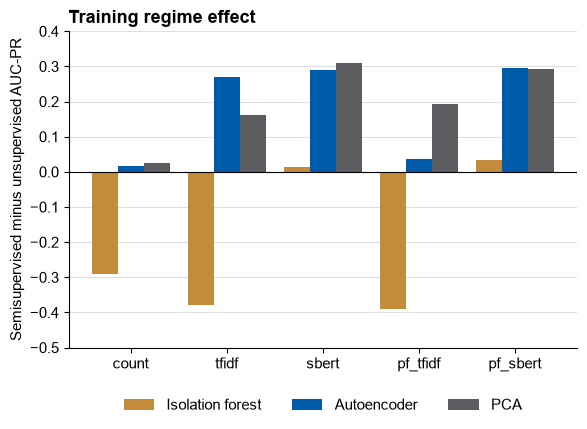

In [19]:
import matplotlib.pyplot as plt

# UP colours used in the slides
UP_RED, UP_BLUE, UP_GOLD, UP_GREY, UP_LIGHTBLUE = "#D71C33", "#005BAA", "#C48B3B", "#5C5C61", "#9DBFE3"
plt.rcParams.update({"font.family": "Arial", "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#DDDDDD",
                     "axes.axisbelow": True})
MODEL = {"iforest": "IF", "autoencoder": "AE", "pca": "PCA"}
REGIME = {"unsupervised": "unsup", "semi_supervised": "semi"}

# ---- Figure 1 (RQ1): template tfidf vs parser-free pf_tfidf, same detector and regime
rq1 = (grid[grid.feature_set.isin(["tfidf", "pf_tfidf"])]
       .pivot_table(index=["model", "regime"], columns="feature_set", values="auc_pr")
       .reindex([(m, r) for m in ["iforest", "autoencoder", "pca"] for r in ["unsupervised", "semi_supervised"]]))
labels = [f"{MODEL[m]} {REGIME[r]}" for m, r in rq1.index]
y = np.arange(len(rq1))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.barh(y - 0.2, rq1["tfidf"], 0.4, color=UP_GREY, label="Template (tfidf)")
ax.barh(y + 0.2, rq1["pf_tfidf"], 0.4, color=UP_RED, label="Parser-free (pf_tfidf)")
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, 0.8)
ax.set_xlabel("Test AUC-PR")
ax.grid(axis="y", visible=False)
ax.set_title("RQ1: parser-free vs template", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.45, -0.13))
fig.tight_layout()
fig.savefig(FIG / "pres_rq1_pairs.png", dpi=200)
plt.show()

# ---- Figure 2 (RQ2): isolation forest, unsupervised, chronological vs random split
order = ["count", "tfidf", "sbert", "pf_tfidf", "pf_sbert"]
rq2 = (splits[(splits.model == "iforest") & (splits.regime == "unsupervised")]
       .set_index("feature_set").reindex(order))
x = np.arange(len(rq2))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.bar(x - 0.2, rq2["chrono_auc_pr"], 0.4, yerr=rq2["chrono_auc_pr_sd"], capsize=3,
       color=UP_BLUE, label="Chronological")
ax.bar(x + 0.2, rq2["random_auc_pr_mean"], 0.4, yerr=rq2["random_auc_pr_sd"], capsize=3,
       color=UP_LIGHTBLUE, label="Random")
ax.set_xticks(x, order)
ax.set_ylim(0, 0.8)
ax.set_ylabel("Test AUC-PR")
ax.grid(axis="x", visible=False)
ax.set_title("RQ2: isolation forest, unsupervised", loc="left", fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "pres_rq2_splits.png", dpi=200)
plt.show()

# ---- Figure 3 (Discussion): semi-supervised minus unsupervised AUC-PR, chronological split
delta = reg["semi_minus_unsup"].unstack("model").reindex(order)[["iforest", "autoencoder", "pca"]]
fig, ax = plt.subplots(figsize=(6, 4.5))
for i, (m, c) in enumerate(zip(delta.columns, [UP_GOLD, UP_BLUE, UP_GREY])):
    ax.bar(x + (i - 1) * 0.27, delta[m], 0.27, color=c, label={"iforest": "Isolation forest",
           "autoencoder": "Autoencoder", "pca": "PCA"}[m])
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, order)
ax.set_ylim(-0.5, 0.4)
ax.set_ylabel("Semisupervised minus unsupervised AUC-PR")
ax.grid(axis="x", visible=False)
ax.set_title("Training regime effect", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.25))
fig.tight_layout()
fig.savefig(FIG / "pres_regime_delta.png", dpi=200)
plt.show()
